In [16]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy.stats import ttest_1samp

# Q2

p<.05 in 37/500 times.


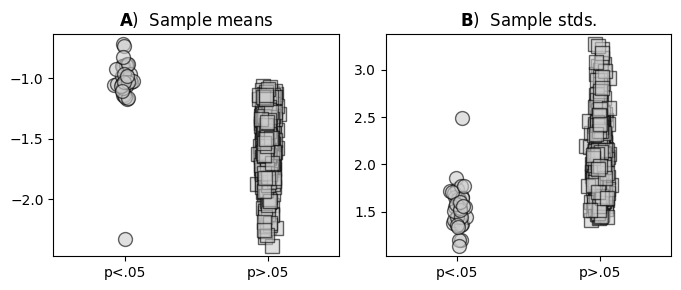

In [26]:
# how often do we get subthreshold results?
N = 50
h0 = -np.pi / 2

nExps = 500
issig = np.zeros(nExps, dtype=bool)  # variable type 'bool' for convenience in plotting
means = np.zeros(nExps)
stds = np.zeros(nExps)

# run the experiment
#   (Note: For a small extra challenge, you could re-implement this without
#          a for-loop using matrix input, after completing the next exercise.)
for i in range(nExps):
    # generate data and store the mean/std
    X = stats.laplace_asymmetric.rvs(2, size=N)
    means[i] = np.mean(X)
    stds[i] = np.std(X, ddof=1)

    # run the ttest and store if "significant"
    r = stats.ttest_1samp(X, h0)
    issig[i] = r.pvalue < .05

# print the results
print(f'p<.05 in {np.sum(issig)}/{nExps} times.')

# show the results
_, axs = plt.subplots(1, 2, figsize=(7, 3))

# means
axs[0].plot(np.random.randn(sum(issig)) / 40, means[issig],
            'ko', markersize=10, markerfacecolor=(.8, .8, .8), alpha=.6)
axs[0].plot(np.random.randn(sum(~issig)) / 40 + 1, means[~issig],
            'ks', markersize=10, markerfacecolor=(.8, .8, .8), alpha=.6)
axs[0].set(xlim=[-.5, 1.5], xticks=[0, 1], xticklabels=['p<.05', 'p>.05'],
           title=r'$\bf{A}$)  Sample means')

# stds
axs[1].plot(np.random.randn(sum(issig)) / 40, stds[issig],
            'ko', markersize=10, markerfacecolor=(.8, .8, .8), alpha=.6)
axs[1].plot(np.random.randn(sum(~issig)) / 40 + 1, stds[~issig],
            'ks', markersize=10, markerfacecolor=(.8, .8, .8), alpha=.6)
axs[1].set(xlim=[-.5, 1.5], xticks=[0, 1], xticklabels=['p<.05', 'p>.05'],
           title=r'$\bf{B}$)  Sample stds.')

plt.tight_layout()
plt.show()

"What is different about those subthreshold datasets?
It is interesting, though not surprising, to see that the "signif-
icant" samples had — purely by chance — means that were
at the edges of the distribution, and also relatively small sam-
ple standard deviations. It is not surprising because the way
we binarized the results selected for samples that have these
characteristics.
I sometimes find these kinds of simulations troubling. There
is one of two possible states of the world here: Either HA is
correct or it is incorrect. If it is correct, then we have lots
of Type-II errors (incorrectly failing to reject H0). And if HA
is incorrect, then we have quite a few false alarms. It would
be nice if statistics would give us an absolute result that we
could absolutely trust; but even in simulated data, all we get
are probabilities that help guide our decisions."

# Q3

"The scipy function stats.ttest_1samp accepts a matrix as
input, with rows corresponding to data observations and columns
corresponding to datasets. The function output will be a vec-
tor of t- and p-values, one for each dataset. Thus, if you have
multiple datasets of the same sample size, you can run t-tests
on all datasets at once, without a for-loop."

In [11]:
cols = 25
data = np.random.normal(1, 1, (40, cols))

# 1
matrix = ttest_1samp(data, 0).statistic

# 2
vector_res = np.zeros(cols)
for i in range(cols):
    vector_res[i] = ttest_1samp(data[:, i], 0).statistic

print('Matrix  |  Vector')
print('--------|--------')
for i in range(cols):
    print(f'{matrix[i]:.4f}  |  {vector_res[i]:.4f}')

Matrix  |  Vector
--------|--------
7.6814  |  7.6814
7.8281  |  7.8281
7.5214  |  7.5214
5.0232  |  5.0232
4.8473  |  4.8473
7.0929  |  7.0929
7.3388  |  7.3388
6.7575  |  6.7575
7.2297  |  7.2297
5.2058  |  5.2058
6.4341  |  6.4341
6.7831  |  6.7831
5.7227  |  5.7227
6.6487  |  6.6487
6.5367  |  6.5367
6.0506  |  6.0506
5.2632  |  5.2632
5.3524  |  5.3524
6.4538  |  6.4538
9.1949  |  9.1949
6.2218  |  6.2218
6.2725  |  6.2725
7.6513  |  7.6513
6.5214  |  6.5214
7.1497  |  7.1497


# Q5
"No, it doesn't really matter - to use population std or empirical std -, because even with N=40, the sample standard deviation
is a fairly accurate estimate of the population standard deviation, certainly for
this range of standard deviation values."

# Q6
"One more exercise on the one-sample t-test. Here I want to
impress upon you the concept that small effect sizes can be
statistically significant with large sample sizes. This has con-
siderable implications both for detecting small effects, and for
the risk of false alarms in large datasets."

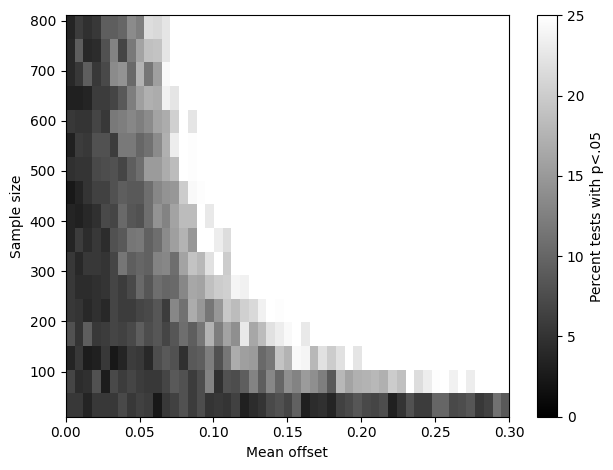

In [27]:
nExperiments = 250
meanoffsets = np.linspace(0, .3, 51)
samplesizes = np.arange(10, 811, step=50)

# initialize
propSig = np.zeros((len(samplesizes), len(meanoffsets)))

# loop over sample sizes
for sidx, ssize in enumerate(samplesizes):

    # loop over effect sizes
    for eidx, effect in enumerate(meanoffsets):
        # generate the data
        X = np.random.normal(loc=effect, scale=1.5, size=(ssize, nExperiments))

        # run the t-test and store the results
        T = stats.ttest_1samp(X, 0)
        propSig[sidx, eidx] = 100 * np.mean(T.pvalue < .05)

# visualize in a matrix
plt.imshow(propSig, extent=[meanoffsets[0], meanoffsets[-1], samplesizes[0], samplesizes[-1]],
           vmin=0, vmax=25, origin='lower', aspect='auto', cmap='gray')
plt.xlabel('Mean offset')
plt.ylabel('Sample size')
cbar = plt.colorbar()
cbar.set_label('Percent tests with p<.05')

plt.tight_layout()
plt.show()

"The key take-home message of this exercise is that the smaller
the sample size, the larger the effect size needs to be to identify
a significant result. Alternatively: If the sample is very large,
even small effects can become statistically significant."

# Q7
"Let’s combine data transformations with the paired-samples
t-test. The idea will be to re-run the t-test on the "reading
comprehension" data (data were presented on page 414 and are
also printed in the online code) after various transformations."

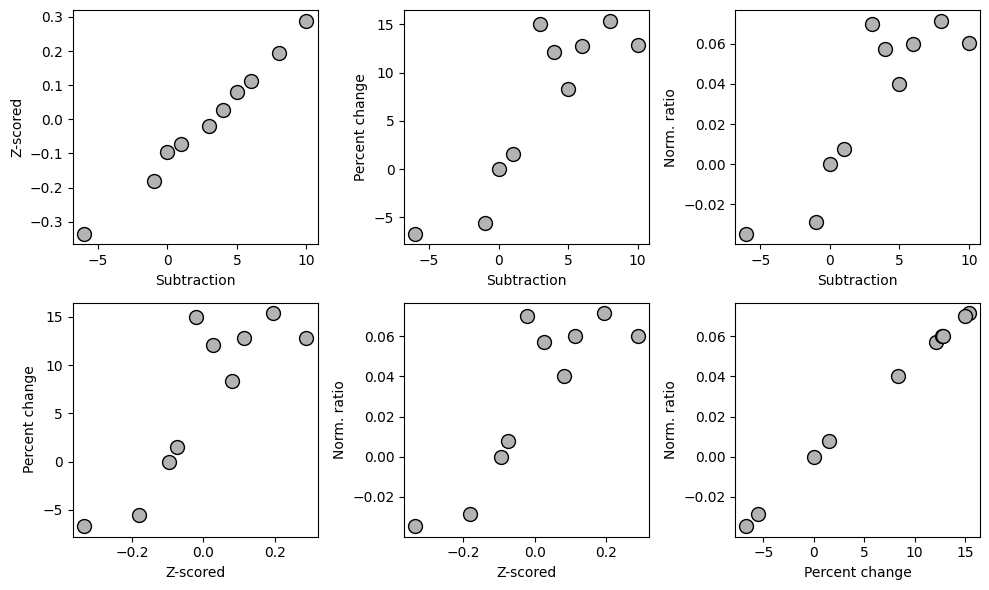

In [17]:
n = np.array([60, 52, 90, 20, 33, 95, 18, 47, 78, 65])
q = np.array([65, 60, 84, 23, 37, 95, 17, 53, 88, 66])
ss = len(n)

y1 = q - n
y2 = stats.zscore(q) - stats.zscore(n)
y3 = 100 * y1 / n
y4 = y1 / (q + n)

# plot
_, axs = plt.subplots(2, 3, figsize=(10, 6))
axs[0, 0].plot(y1, y2, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[0, 0].set(xlabel='Subtraction', ylabel='Z-scored')

axs[0, 1].plot(y1, y3, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[0, 1].set(xlabel='Subtraction', ylabel='Percent change')

axs[0, 2].plot(y1, y4, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[0, 2].set(xlabel='Subtraction', ylabel='Norm. ratio')

axs[1, 0].plot(y2, y3, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[1, 0].set(xlabel='Z-scored', ylabel='Percent change')

axs[1, 1].plot(y2, y4, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[1, 1].set(xlabel='Z-scored', ylabel='Norm. ratio')

axs[1, 2].plot(y3, y4, 'ko', markersize=10, markerfacecolor=(.7, .7, .7))
axs[1, 2].set(xlabel='Percent change', ylabel='Norm. ratio')

plt.tight_layout()
plt.show()

"Notice that all trans-
formations are strongly correlated with each other, but they
are not identical. Y1 and Y2, and Y3 and Y4, are the most
closely related. Now for the real question: Do these transformations have a
noteworthy impact on the results of the t-test?"

In [19]:
# t-tests
tSub = stats.ttest_1samp(y1, 0)
tPct = stats.ttest_1samp(y2, 0)
tsbz = stats.ttest_1samp(y3, 0)
tnrt = stats.ttest_1samp(y4, 0)

# print the results
print(f'Subtraction (Y1): t({tSub.df})={tSub.statistic:.3f}, p<{tSub.pvalue:.3f}')
print(f'Percent chg (Y2): t({tPct.df})={tPct.statistic:.3f}, p<{tPct.pvalue:.3f}')
print(f'Z subtract  (Y3): t({tsbz.df})={tsbz.statistic:.3f}, p<{tsbz.pvalue:.3f}')
print(f'Norm. ratio (Y4): t({tnrt.df})={tnrt.statistic:.3f}, p<{tnrt.pvalue:.3f}')

Subtraction (Y1): t(9)=2.023, p<0.074
Percent chg (Y2): t(9)=0.000, p<1.000
Z subtract  (Y3): t(9)=2.445, p<0.037
Norm. ratio (Y4): t(9)=2.353, p<0.043


"Yikes! The data transformation had an extreme impact on the
results — changing the finding from non-significant to signif-
icant. That is... thought-provoking, disturbing, and fascinat-
ing.
Before discussing the implications, let me discuss the z-score
subtraction result. Are you surprised that the t-value is zero?
It may seem strange at first, because the z-transformed vari-
able is nearly perfectly correlated with the "raw" subtraction
variable. But, recall that z-transformed data have a mean of
zero, which means the numerator of the t-ratio is zero minus
zero.
The fact that applying different transformations of the same
data can make the finding significant or non-significant high-
lights the importance of understanding the underlying assump-
tions of the statistical test, and of the justification of the trans-
formation. Applying transformations arbitrarily or solely to
obtain a significant result can lead to false conclusions, is bad
statistical practice, and is possibly unethical. As I discussed in
Chapter 6, any transformation should be justifiable and cause
minimal change to the analysis.
In a broader sense, analyses whose statistical outcomes vary
considerably after minor variations in analysis parameters or
design decisions tend to be less reliable. In other words, re-
sults that demonstrate robustness across a range of analytical
choices inspire greater confidence."

# Q9
"In this exercise, you will explore whether the homogeneity of
variance assumption is crucial for evaluating the results of an
independent t-test."

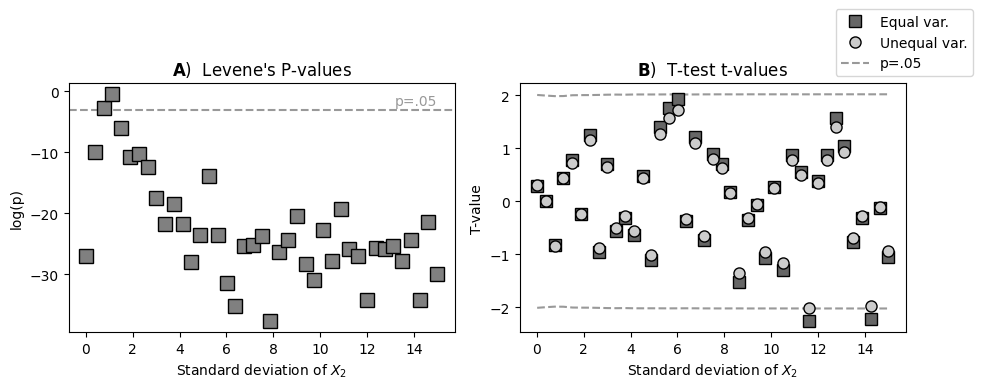

In [22]:
stds = np.linspace(.01, 15, 41)

results = np.zeros((3, len(stds)))
t_crit = np.zeros(len(stds))

for i, std in enumerate(stds):
    x1 = np.random.normal(1, 1, 50)
    x2 = np.random.normal(1.1, std, 40)

    # Levene
    results[0, i] = np.log(stats.levene(x1, x2).pvalue)

    # t-values
    same_var = stats.ttest_ind(x1, x2, equal_var=True)
    diff_var = stats.ttest_ind(x1, x2, equal_var=False)
    results[1, i] = same_var.statistic
    results[2, i] = diff_var.statistic

    # compute df for tCrit
    s1, s2 = np.var(x1, ddof=1), np.var(x2, ddof=1)
    n1, n2 = len(x1), len(x2)
    df_num = (s1 / n1 + s2 / n2) ** 2
    df_den = s1 ** 2 / (n1 ** 2 * (n1 - 1)) + s2 ** 2 / (n2 ** 2 * (n2 - 1))

    t_crit[i] = stats.t.isf(0.05 / 2, df_num / df_den)

# plot
_, axs = plt.subplots(1, 2, figsize=(10, 4))

# levene's test results
axs[0].plot(stds, results[0, :], 'ks', markersize=10, markerfacecolor='gray')
axs[0].axhline(np.log(.05), color=(.6, .6, .6), linestyle='--', zorder=-1)
axs[0].text(np.max(stds), np.log(.1), 'p=.05', ha='right', color=(.6, .6, .6))
axs[0].set(xlabel=r'Standard deviation of $X_2$', ylabel='log(p)', title=r"$\bf{A}$)  Levene's P-values")

# t-tests
axs[1].plot(stds, results[1, :], 'ks', markersize=8, markerfacecolor=(.4, .4, .4), label='Equal var.')
axs[1].plot(stds, results[2, :], 'ko', markersize=8, markerfacecolor=(.8, .8, .8), label='Unequal var.')
axs[1].plot(stds, t_crit, '--', color=(.6, .6, .6), zorder=-1, label='p=.05')
axs[1].plot(stds, -t_crit, '--', color=(.6, .6, .6), zorder=-1)
axs[1].set(xlabel=r'Standard deviation of $X_2$', ylabel='T-value', title=r"$\bf{B}$)  T-test t-values")
axs[1].legend(fontsize=10, bbox_to_anchor=[.8, 1])

plt.tight_layout()
plt.show()

"The key question in this exercise is whether assuming homo-
geneity of variance matters. The gray squares and light-gray
circles in panel B do not perfectly overlap, meaning that there
is at least a numerical implication of the assumption.
The more important question is whether you would draw dif-
ferent conclusions about the data based on the formula adjustment.
To answer that question, look for cases where the result crosses
the significance threshold without vs. with the adaptation for
unequal variance.
You can also see that the t-values are slightly
inflated (that is, further from zero) when assuming equal vari-
ance. On the other hand, the statistical significance label
would be the same for most of the tests performed here."

"The conclusion is using equal vs. unequal variance in the
independent-samples t-test may not have a substantial impact
on the conclusions of your research, but it’s good to use the
correct form to be on the safe side."

# Q11
"The purpose of this exercise is to explore the relationship
between the p-value from the t-test and the two measures of
effect size."

In [24]:
meanoffsets = np.linspace(0, 2, 71)
samplesizes = np.arange(10, 811, step=50)

# initialize
pvals = np.zeros((len(samplesizes), len(meanoffsets)))
cohend = np.zeros((len(samplesizes), len(meanoffsets)))
r2 = np.zeros((len(samplesizes), len(meanoffsets)))

# loop over sample sizes
for sidx, ssize in enumerate(samplesizes):
    # loop over effect sizes
    for eidx, effect in enumerate(meanoffsets):
        # generate the data
        X = np.random.normal(loc=effect, scale=1.5, size=ssize)

        # run the t-test and store the results
        T = stats.ttest_1samp(X, 0)
        pvals[sidx, eidx] = T.pvalue

        # Cohen's d
        cohend[sidx, eidx] = np.abs(np.mean(X) / np.std(X, ddof=1))

        # R^2
        r2[sidx, eidx] = T.statistic ** 2 / (T.statistic ** 2 + T.df)

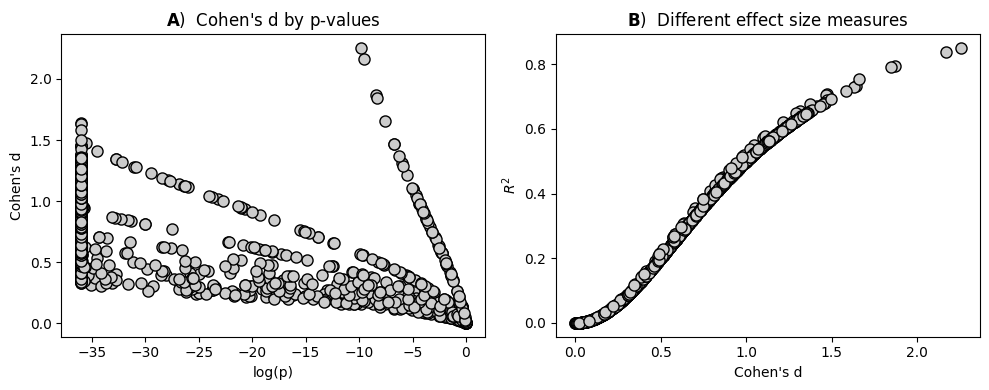

In [25]:
_, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].plot(np.log(pvals + np.finfo(float).eps), cohend, 'ko', markersize=8, markerfacecolor=(.8, .8, .8))
axs[0].set(xlabel='log(p)', ylabel="Cohen's d")
axs[0].set_title(r"$\bf{A}$)  Cohen's d by p-values")

axs[1].plot(cohend, r2, 'ko', markersize=8, markerfacecolor=(.8, .8, .8))
axs[1].set(xlabel="Cohen's d", ylabel=r'$R^2$')
axs[1].set_title(r'$\bf{B}$)  Different effect size measures')

plt.tight_layout()
plt.show()

". You can see that
there is a tight relationship between Cohen’s d and R2, al-
though it is a non-linear relationship. Cohen’s d and R2 are
not identical, but they provide very similar information.
On the other hand, there are relationships between the p-value
and Cohen’s d, but each relationship (that is, each "string"
of dots) depends on sample size. The important take-home
message from this exercise is that the same p-value can have
very different effect sizes; and the same effect size can have
very p-values. This is an illustration of how a p-value cannot
be used to infer effect size. Indeed, the points in the lower-
left of panel A show tiny p-values (i.e., extremely statistically
significant) from very small effect sizes, which happens because
of large sample sizes."